# AI use by Saudi businesses, by sector, 2024 and 2025

**Which sectors of Saudi business used AI in 2025, how fast did use grow from 2024, and which sectors still trail?**

This notebook recomputes the key figures from the raw readings and checks that they match the build script output (`data/processed`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
raw = pd.read_csv('../data/raw/ai_use_readings.csv')
sources = pd.read_csv('../data/raw/sources.csv')
print(raw.shape, 'readings from', raw.source_id.nunique(), 'documents')
print(raw.groupby('year').size())

(138, 8) readings from 10 documents
year
2024    72
2025    66
dtype: int64


## 1. Data checks

Every figure must read the same in every document that prints it. Readings set aside are those where an outlet paired a value with a different sector label from GASTAT's own chart order.

In [2]:
aside = raw[raw.note.fillna('').str.startswith('set aside')]
print(aside[['year','sector','raw','source_id','note']].to_string(index=False))
used = raw.drop(aside.index)
spread = used.groupby(['year','isic_section']).value.nunique()
assert (spread == 1).all(), spread[spread > 1]
print('All', len(spread), 'figures agree across documents')
print('Missing values:', used.value.isna().sum(), '| Range:', used.value.min(), 'to', used.value.max())

 year                             sector  raw source_id                                                                                                                              note
 2024                       Construction 25.8        S8          set aside: this value belongs to water supply and sewerage in GASTAT order; the outlet appears to have shifted one label
 2024       Human health and social work 29.9        S8 set aside: this value belongs to arts, entertainment and recreation in GASTAT order; the outlet appears to have shifted one label
 2024 Arts, entertainment and recreation 20.1        S8           set aside: this value belongs to other service activities in GASTAT order; the outlet appears to have shifted one label
 2024                       Construction 25.8       S10          set aside: this value belongs to water supply and sewerage in GASTAT order; the outlet appears to have shifted one label
 2024       Human health and social work 29.9       S10 set aside: thi

In [3]:
rec = used.groupby(['year','isic_section','sector']).value.first().reset_index()
wide = rec.pivot(index=['isic_section','sector'], columns='year', values='value').reset_index()
wide.columns = ['isic_section','sector','pct_2024','pct_2025']
wide['change_pts'] = (wide.pct_2025 - wide.pct_2024).round(1)
nat = wide[wide.isic_section=='ALL'].iloc[0]
sec = wide[wide.isic_section!='ALL'].sort_values('pct_2025', ascending=False)
print(f'National: {nat.pct_2024} (2024) -> {nat.pct_2025} (2025), +{nat.change_pts} pts, {100*(nat.pct_2025/nat.pct_2024-1):.1f}% relative')
sec

National: 27.6 (2024) -> 33.1 (2025), +5.5 pts, 19.9% relative


,isic_section,sector,pct_2024,pct_2025,change_pts
10,J,Information and communication,52.8,61.1,8.3
11,K,Financial and insurance,44.7,52.9,8.2
15,P,Education,42.1,51.0,8.9
8,H,Transportation and storage,38.3,44.4,6.1
13,M,"Professional, scientific and technical",39.2,43.9,4.7
2,B,Mining and quarrying,32.4,41.8,9.4
17,R,"Arts, entertainment and recreation",29.9,36.3,6.4
16,Q,Human health and social work,31.8,35.6,3.8
4,D,Electricity and gas supply,25.7,35.4,9.7
5,E,Water supply and sewerage,25.8,34.9,9.1


## 2. Recompute the headline figures and compare with the build script

In [4]:
built = pd.read_csv('../data/processed/ai_use_by_sector.csv')
m = sec.merge(built, on='isic_section', suffixes=('','_b'))
assert (m.pct_2024 == m.pct_2024_b).all() and (m.pct_2025 == m.pct_2025_b).all() and (m.change_pts == m.change_pts_b).all()
head = pd.read_csv('../data/processed/headline_figures.csv').set_index('measure').value
assert float(head['national_2025_pct']) == nat.pct_2025
assert float(head['national_change_pts']) == round(nat.pct_2025 - nat.pct_2024, 1)
assert int(head['sectors_rising']) == (sec.change_pts > 0).sum() == 18
assert int(head['sectors_above_national_2025']) == (sec.pct_2025 > nat.pct_2025).sum() == 13
assert float(head['gap_high_low_2025_pts']) == round(sec.pct_2025.max() - sec.pct_2025.min(), 1) == 34.4
# GASTAT prints growth of 20.0%; check it lies inside the rounding range of the two national rates
lo = (nat.pct_2025-0.05)/(nat.pct_2024+0.05)-1; hi = (nat.pct_2025+0.05)/(nat.pct_2024-0.05)-1
assert lo <= 0.2005 and hi >= 0.1995
print(f'Published growth 20.0% sits inside the implied range {100*lo:.2f}% to {100*hi:.2f}%')
print('All headline figures match the build script')
head

Published growth 20.0% sits inside the implied range 19.53% to 20.33%
All headline figures match the build script


measure
national_2025_pct                                            33.1
national_2024_pct                                            27.6
national_change_pts                                           5.5
national_change_rel_pct                                      19.9
sectors_rising                                                 18
sectors_above_national_2025                                    13
highest_sector_2025            Information and communication 61.1
lowest_sector_2025                  Other service activities 26.7
gap_high_low_2025_pts                                        34.4
gap_high_low_2024_pts                                        32.7
largest_rise                       Electricity and gas supply 9.7
smallest_rise                                     Real estate 3.6
median_sector_change_pts                                      6.5
Name: value, dtype: str

## 3. Which sectors sit below the national rate, and which rose least

In [5]:
print(sec[sec.pct_2025 < nat.pct_2025][['sector','pct_2025']].to_string(index=False))
print()
print(sec.sort_values('change_pts')[['sector','pct_2024','pct_2025','change_pts']].head(5).to_string(index=False))
print('\nMedian sector rise:', sec.change_pts.median(), 'points')

                                              sector  pct_2025
                                         Real estate      31.8
                                       Manufacturing      30.7
                  Administrative and support service      30.4
Wholesale and retail trade; repair of motor vehicles      30.2
                            Other service activities      26.7

                                sector  pct_2024  pct_2025  change_pts
                           Real estate      28.2      31.8         3.6
          Human health and social work      31.8      35.6         3.8
                         Manufacturing      26.0      30.7         4.7
Professional, scientific and technical      39.2      43.9         4.7
                          Construction      29.0      33.8         4.8

Median sector rise: 6.5 points


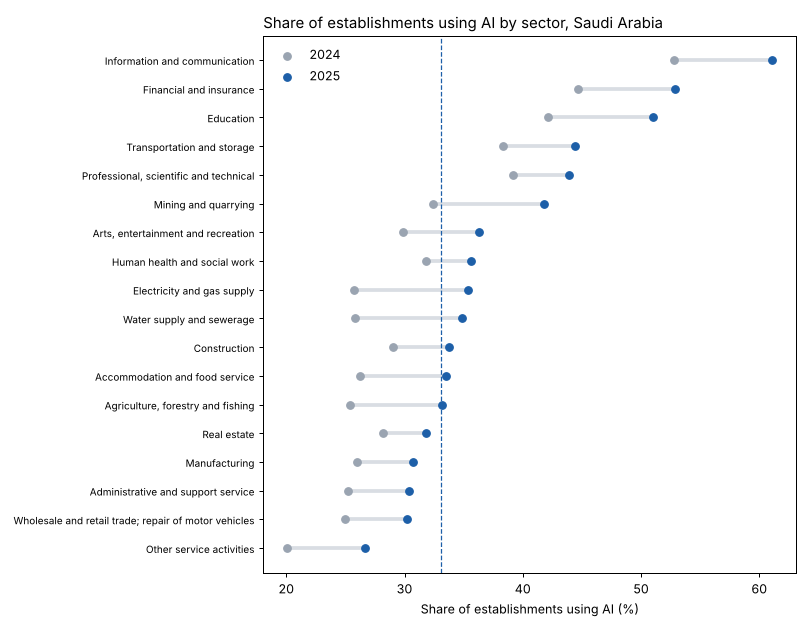

In [6]:
s = sec.sort_values('pct_2025')
fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(range(len(s)), s.pct_2024, s.pct_2025, color='#d9dde3', lw=3)
ax.scatter(s.pct_2024, range(len(s)), color='#9aa4b1', label='2024', zorder=3)
ax.scatter(s.pct_2025, range(len(s)), color='#1d5fa8', label='2025', zorder=3)
ax.axvline(nat.pct_2025, ls='--', color='#1d5fa8', lw=1)
ax.set_yticks(range(len(s))); ax.set_yticklabels(s.sector, fontsize=8)
ax.set_xlabel('Share of establishments using AI (%)'); ax.legend(frameon=False)
ax.set_title('Share of establishments using AI by sector, Saudi Arabia', loc='left')
plt.tight_layout(); plt.show()

## 4. How well each figure is confirmed

In [7]:
tidy = pd.read_csv('../data/processed/ai_use_tidy.csv')
print(tidy.groupby(['year','verification']).size())

year  verification      
2024  official-and-press    12
      one-document           7
2025  official-and-press     6
      one-document          13
dtype: int64
